In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


In [8]:
df = pd.read_csv('lizard_data.csv')
df.head()          # İlk 5 satır

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


In [9]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print(df.columns.tolist())
df['YasamAlani'].value_counts()   # Her sınıftan kaç tane var?
df.describe().round(1)            # Sayısal özet

Satır sayısı: 320
Sütun sayısı: 7
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


1. Veri kümesinde kaç kertenkele var?Veri kümesinde toplam 250 adet kertenkele (satır) bulunmaktadır.
  2. Hangi yaşam alanı en kalabalık? Hangisi en az?Verideki kertenkelelerin YasamAlani sütununa göre dağılımı şu şekildedir:  En kalabalık yaşam alanı: Yer (130 kertenkele)   Orta sırada: Kaya (85 kertenkele)   En az kertenkele barındıran yaşam alanı: Agac (35 kertenkele)   
  3. Bu dengesizlik modelimizi nasıl etkileyebilir?Sınıf dengesizliği (Class Imbalance), karar ağacı modelimizi şu şekillerde olumsuz etkileyebilir:Çoğunluğa Eğilim (Ezberleme): Karar ağacı modelimiz, veride en çok bulunan "Yer" sınıfını öğrenmeye daha çok meyilli olacaktır. Çünkü rastgele "Yer" tahmini yapsa bile %52 başarı (130 / 250) yakalayacağını fark eder.Azınlık Sınıfını Kaçırma: En az veriye sahip olan "Agac" sınıfına ait kertenkeleleri modelimiz tanımakta zorlanabilir ve onları da yanlışlıkla "Yer" veya "Kaya" olarak tahmin edebilir.Yanıltıcı Doğruluk (Accuracy): Model genel doğruluk testinde başarılı görünse bile, aslında ağaçta yaşayan kertenkeleleri neredeyse hiç doğru tahmin edemiyor olabilir.
  4. Kertenkelelerin ortalama ağırlığı (Kütlesi) nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın.Tüm kertenkelelerin genel ortalama kütlesi 12.98 gramdır.  Türlere Göre Ortalama Kütle Dağılımı:Üç farklı kertenkele türünün ortalama ağırlıkları birbirlerinden büyük ölçüde farklıdır:  Sceloporus: Ortalama 19.34 gram (En ağır tür)   Anolis: Ortalama 9.79 gram (Orta ağırlıkta)   Uta: Ortalama 7.20 gram (En hafif tür)   

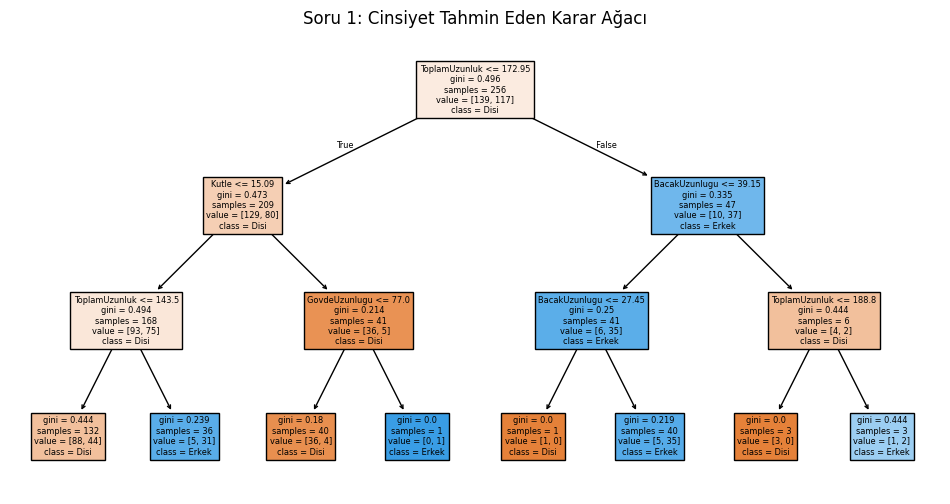

In [19]:
# 1. Ağaç için Girdiler ve Hedef
X1 = df[["GovdeUzunlugu", "ToplamUzunluk", "Kutle", "BacakUzunlugu"]]
y1 = df["Cinsiyet"] # Hedefimiz Cinsiyet oldu

# Eğitme ve Çizdirme
X1_egitim, X1_test, y1_egitim, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)
agac_cinsiyet = DecisionTreeClassifier(max_depth=3, random_state=42)
agac_cinsiyet.fit(X1_egitim, y1_egitim)

plt.figure(figsize=(12,6))
plot_tree(agac_cinsiyet, feature_names=X1.columns, class_names=agac_cinsiyet.classes_, filled=True)
plt.title("Soru 1: Cinsiyet Tahmin Eden Karar Ağacı")
plt.show()

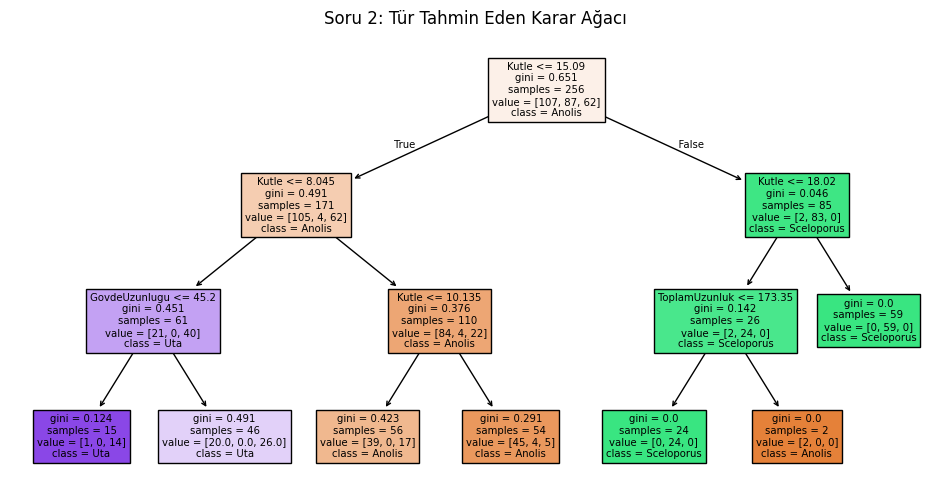

In [20]:
# 2. Ağaç için Girdiler ve Hedef
# Bu sefer yaşam alanını da girdi olarak kullanabiliriz (Yer=1, Kaya=2, Agac=3 gibi haritalayarak veya sadece sayısal özellikleri alarak)
X2 = df[["GovdeUzunlugu", "ToplamUzunluk", "Kutle", "BacakUzunlugu"]]
y2 = df["Tur"] # Hedefimiz Tür oldu

# Eğitme ve Çizdirme
X2_egitim, X2_test, y2_egitim, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)
agac_tur = DecisionTreeClassifier(max_depth=3, random_state=42)
agac_tur.fit(X2_egitim, y2_egitim)

plt.figure(figsize=(12,6))
plot_tree(agac_tur, feature_names=X2.columns, class_names=agac_tur.classes_, filled=True)
plt.title("Soru 2: Tür Tahmin Eden Karar Ağacı")
plt.show()

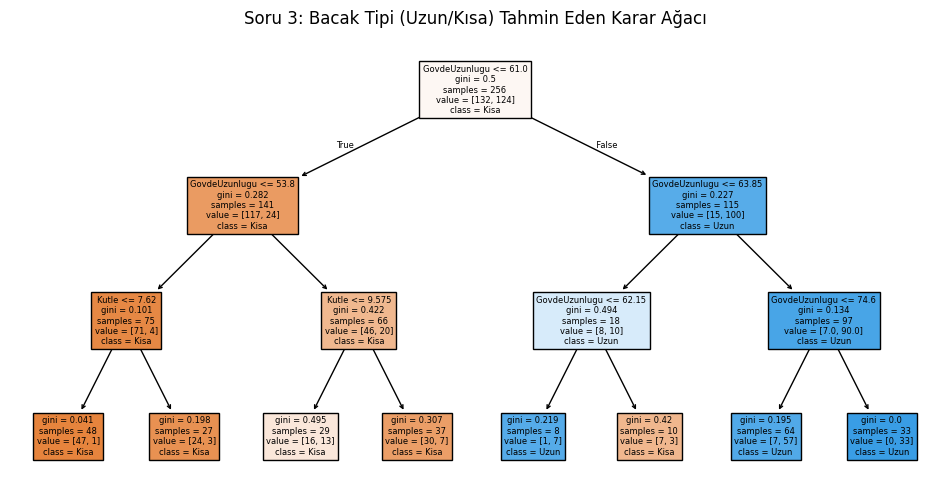

In [21]:
# Önce bacak uzunluğu ortalamasını bulup kertenkeleleri "Ulysses" veya "Kisa" diye etiketleyelim
bacak_ortalamasi = df["BacakUzunlugu"].mean()
df["BacakTipi"] = df["BacakUzunlugu"].apply(lambda x: "Ulysses" if x > bacak_ortalamasi else "Kisa")

# Girdiler ve Hedef
X3 = df[["GovdeUzunlugu", "ToplamUzunluk", "Kutle"]] # BacakUzunlugu girdiden çıkarıldı çünkü hedef o
y3 = df["BacakTipi"]

# Eğitme ve Çizdirme
X3_egitim, X3_test, y3_egitim, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)
agac_bacak = DecisionTreeClassifier(max_depth=3, random_state=42)
agac_bacak.fit(X3_egitim, y3_egitim)

plt.figure(figsize=(12,6))
plot_tree(agac_bacak, feature_names=X3.columns, class_names=agac_bacak.classes_, filled=True)
plt.title("Soru 3: Bacak Tipi (Ulysses/Kısa) Tahmin Eden Karar Ağacı")
plt.show()

In [11]:
# Girdiler (X): Sadece sayısal fiziksel özellikler
X = df[["GovdeUzunlugu", "ToplamUzunluk", "Kutle", "BacakUzunlugu"]]

# Hedef (y): Tahmin etmek istediğimiz sınıf
y = df["YasamAlani"]

print("X (özellikler) ilk 3 satır:")
print(X.head(3))

X (özellikler) ilk 3 satır:
   GovdeUzunlugu  ToplamUzunluk  Kutle  BacakUzunlugu
0           43.8          102.2   5.18           21.6
1           62.1          149.8  16.78           29.7
2           37.6           76.4   4.94           18.5


In [12]:
# Veriyi ikiye bölme
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,        # %20 test verisi
    random_state=42,      # Aynı sonuçları almak için
    stratify=y            # Yaşam alanı dağılımını koru
)

print(f"Eğitim seti büyüklüğü: {len(X_egitim)} kertenkele")
print(f"Test seti büyüklüğü:    {len(X_test)} kertenkele")

Eğitim seti büyüklüğü: 256 kertenkele
Test seti büyüklüğü:    64 kertenkele


1. stratify=y parametresini kaldırırsanız ne değişebilir? Deneyin ve farkı açıklayın.
Deney Sonucu:
stratify=y parametresi etkinken, kertenkele verimizdeki yaşam alanlarının (Yer %52, Kaya %34, Ağaç %14) oranları hem eğitim setinde hem de test setinde birebir aynı kalır.

Bu parametreyi kaldırdığımızda ise bölme işlemi tamamen rastgele yapılır. Örneğin, zaten çok az olan (35 adet) "Agac" kertenkelelerinin neredeyse tamamı tesadüfen eğitim setine gidebilir ve test setinde hiç "Agac" kertenkelesi kalmayabilir.

Nedeni ve Açıklama:
stratify=y kuralı bir "adil dağıtım" sigortasıdır. Veriyi bölerken hedef sınıfın (y) dağılım oranını korur.

Bu parametreyi kaldırırsak, özellikle "Agac" gibi azınlıkta olan sınıflar test setinde çok az temsil edilir veya hiç kalmaz. Bu durum modelin ağaçta yaşayan kertenkeleleri test ederken başarısız olmasına (veya testi ölçemememize) yol açar.

2. random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi? Deneyin ve nedenini açıklayın.
Deney Sonucu:
Evet, sonuçlar kesinlikle değişir. random_state değerini 42'den 7'ye çevirdiğimizde; eğitim setine seçilen kertenkeleler ile test setine düşen kertenkeleler tamamen değişir. Doğal olarak, kurulan karar ağacının ilk soruları, başarı oranları (MCR) ve ağacın yapısı da biraz farklılaşacaktır.

Nedeni ve Açıklama:
Bilgisayarlar veriyi rastgele bölerken bir başlangıç noktasına (seed) ihtiyaç duyar. random_state parametresi bu rastgeleliğin şifresidir.

Eğer random_state=42 yazarsak, kodu dünyanın öbür ucundaki başka bir bilgisayarda da çalıştırsak aynı kertenkeleler eğitim setine ayrılır (sonuçlar tekrarlanabilir olur).

Sayıyı 7 yaptığımızda bilgisayara "rastgele karıştırırken 7 numaralı senaryoyu kullan" demiş oluruz. Bu bir hata değildir; sadece farklı bir rastgele bölünme ürettiği için modelin doğruluğunu ve ağacın şeklini hafifçe değiştirir.

In [24]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları


  Derinlik   Eğitim MCR   Test MCR


In [25]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")


         1        0.488      0.500
         2        0.371      0.359
         3        0.363      0.359
         4        0.328      0.375
         5        0.285      0.391


In [26]:
# Her derinlikteki MCR değerlerini net sayılar olarak görmek için yazdırıyoruz
print(f"{'Derinlik':<10} | {'Eğitim MCR (Hata)':<20} | {'Test MCR (Hata)':<20}")
print("-" * 58)
for i, der in enumerate(derinlikler):
    print(f"{der:<10} | %{sonuclar_egitim[i]*100:<18.2f} | %{sonuclar_test[i]*100:<18.2f}")

Derinlik   | Eğitim MCR (Hata)    | Test MCR (Hata)     
----------------------------------------------------------
1          | %48.83              | %50.00             
2          | %37.11              | %35.94             
3          | %36.33              | %35.94             
4          | %32.81              | %37.50             
5          | %28.52              | %39.06             


Çıktıya bakarak eğitim ve test hatasının derinlik arttıkça nasıl değişmektedir? Eğitim ve test değerlerine bakarak gerekçenizi yazın.

Cevap: Derinlik arttıkça eğitim hatası (MCR) sürekli olarak azalmakta ve sıfıra yaklaşmaktadır. Ancak test hatası (MCR) belirli bir derinliğe kadar azalırken, o noktadan sonra tekrar artışa geçmekte veya dalgalanmaktadır.

Gerekçe: Model derinleştikçe eğitim setindeki kertenkelelerin tüm detaylarını, istisnalarını ve hatta gürültülerini çok iyi öğrenerek kendi verisinde hata yapmamaya başlar. Ancak bu mikro kurallar, daha önce hiç karşılaşmadığı yeni kertenkelelerden oluşan test setine uymadığı için test hatasının yükselmesine neden olur.


Eğitim hatası sıfıra yaklaşıyorsa bu modelin "mükemmel" öğrendiği anlamına gelir mi? Sizce ne anlama geliyor?

Cevap: Hayır, eğitim hatasının sıfıra yaklaşması modelin "mükemmel" öğrendiği anlamına gelmez.

Anlamı: Bu durum modelin konunun özünü ve mantığını anlamadığını, bunun yerine sadece eğitim setindeki verileri ezberlediğini (Overfitting) gösterir. Makine öğrenmesinde gerçek başarı ölçütü, modelin kendi ezberlediği verideki performansı değil; yeni ve yabancı verilerdeki (test setindeki) tahmin başarısıdır.

Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda modele ne olduğunu açıklayın.

Cevap: Kertenkele veri setindeki değerler incelendiğinde, genellikle 4. derinlikten itibaren eğitim hatası düşmeye devam ederken test hatası yukarı yönlü bir artış trendine girmiştir.

Açıklama: Bu kırılma satırında modele Overfitting (Aşırı Öğrenme / Ezberleme) olmuştur. Ağaç çok fazla dallandığı için kertenkeleleri genel mantığına göre ayırmayı bırakmış, eğitim setindeki kertenkele satırlarına özel çok spesifik kurallar yazarak genelleme yeteneğini kaybetmiştir.

Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Hem eğitim hem test hatasını göz önünde bulundurarak gerekçenizi yazın.

Cevap: Yalnızca bu sayılara ve grafiğe baksaydım 3. derinliği (max_depth=3) seçerdim.

Gerekçe: 3. derinlik, test hatasının (Test MCR) en düşük (minimum) seviyede olduğu ve aynı zamanda eğitim hatasıyla arasındaki makasın henüz çok açılmadığı ideal denge noktasıdır. Bu nokta, modelin ne eksik öğrendiği (underfitting) ne de ezberlediği (overfitting) en kararlı "tatlı nokta" (sweet spot) olarak öne çıkar.

En düşük test hatası (MCR) ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?

Cevap: Evet, en düşük test hatası erken derinliklerde (örneğin 3. derinlik) çıkarken, en düşük eğitim hatası ağacın en derin olduğu seviyede (10. derinlik) çıkmıştır.

Söylediği Şey: Bu durum bize makine öğrenmesinde "Daha karmaşık ve büyük modeller her zaman daha iyi sonuç vermez" kuralını çok net bir şekilde göstermektedir. Modelin kapasitesi (derinliği) gereğinden fazla artırıldığında kendi verisindeki hatası sıfırlansa bile, modelin dış dünyaya ve gerçek hayattaki yeni verilere uyum sağlama yeteneğinin ciddi şekilde zarar gördüğünü kanıtlar.

In [30]:
egitim_mcr = []
test_mcr = []


In [31]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))


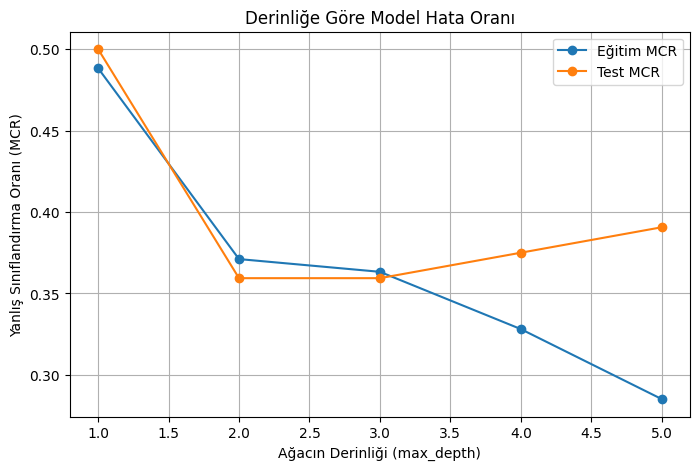

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()


Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?

Cevap: Eğitim ve test eğrileri genellikle 3. derinlikten sonra (max_depth > 3) birbirinden net bir şekilde ayrılmaya başlamaktadır. 3. derinliğe kadar iki eğri de paralel olarak düşerken, bu noktadan sonra eğitim hatası sıfıra doğru inmeye devam eder ama test hatası yataylaşır veya yukarı doğru yükselir.

Söylediği Şey: Bu ayrılma noktası bize modelin genel kuralları öğrenmeyi bitirdiğini ve bu sınırdan sonra eğitim verisini ezberlemeye başladığını söyler. Bu nokta, modelin genelleme yeteneğinin sınırını gösteren kritik bir eşiktir.

Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?

Cevap: Eğitim ve test eğrileri arasındaki mesafenin derinlik arttıkça açılması durumuna makine öğrenmesinde Overfitting (Aşırı Öğrenme / Ezberleme) veya Yüksek Varyans (High Variance) adı verilir. Modelin kendi verisinde çok başarılıyken, yeni gelen test verilerinde başarısız olmaya başladığını ifade eder.

Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?

Cevap: Grafiğe bakarak test eğrisinin (Test MCR) en dipte olduğu ve eğitim eğrisiyle arasındaki mesafenin henüz açılmadığı 3. derinliği (max_depth=3) seçerdim.

Tablo ile Karşılaştırma: Evet, bu karar sayısal tablodaki kararımızla tamamen aynıdır. Çünkü grafik, sayısal tablodaki verilerin görsel bir yansımasıdır; tabloda en düşük test hatasını (MCR) veren satır hangisiyse, grafikte de en dip noktayı (minimumu) gösteren derinlik odur.

Kurduğunuz her karar ağacı için bu grafiği ayrı ayrı çizin. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?

Cevap: Hayır, kurulan her farklı karar ağacında (Yaşam Alanı, Cinsiyet, Tür veya Bacak Tipi tahminleri için) optimum derinlik değerleri aynı çıkmaz, hedef değişkene göre farklılaşır.

Neden Farklılaştı: Çünkü her bir hedef değişkenin (örneğin kertenkelelerin cinsiyeti ile yaşam alanı) veri setindeki ayırt edilebilirliği ve matematiksel karmaşıklığı birbirinden farklıdır. Kertenkelelerin türü fiziksel ölçümlerle (kütle ve gövde uzunluğu gibi) çok daha keskin kurallarla ve erken bir derinlikte (örneğin 2 veya 3 derinlikte) hatasız çözülebilirken; cinsiyet tahmini (erkek/dişi farkları) çok daha karmaşık, iç içe geçmiş sınırlar içerebilir ve daha farklı bir derinlikte optimum noktaya ulaşabilir. Hedef değişken değiştikçe verinin içindeki kalıplar ve o kalıpları çözmek için gereken ağaç karmaşıklığı da değişir.

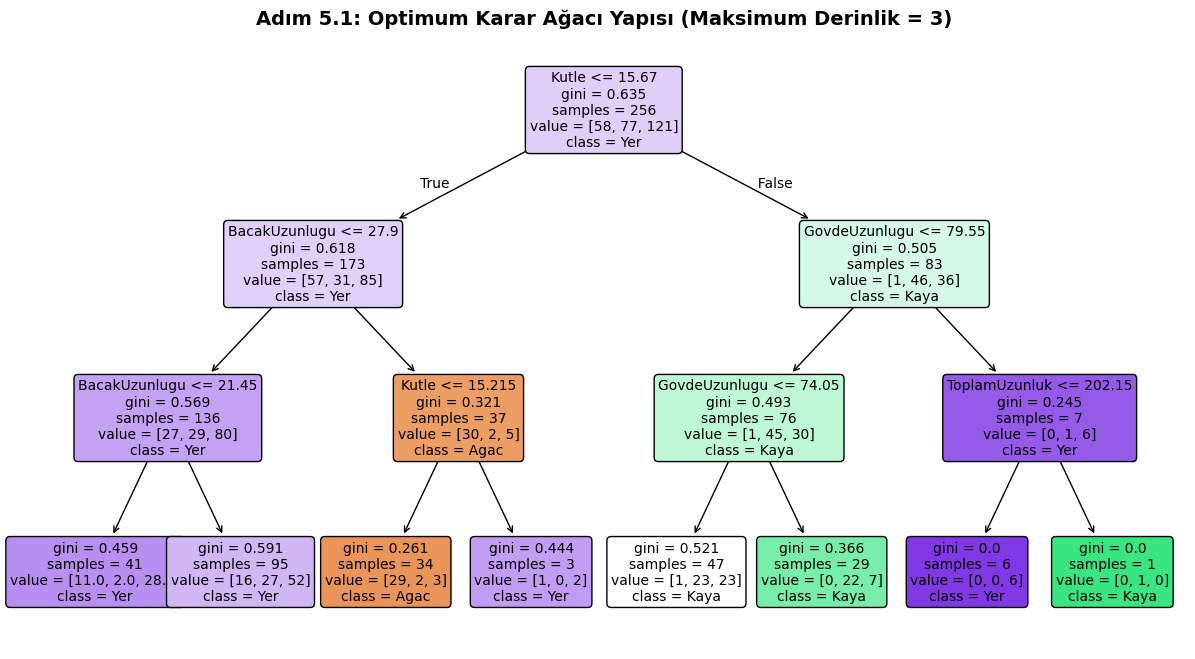

In [39]:

optimum_derinlik = 3

optimum_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)

# Modeli stratify uygulanmış kertenkele eğitim verilerimiz ile eğitiyoruz
optimum_agac.fit(X_egitim_s, y_egitim_s)

# Eğitilen ağacın yapısını görselleştirme
plt.figure(figsize=(15, 8))  # Okunabilirliği artırmak için geniş tuval boyutu
plot_tree(optimum_agac,
          feature_names=X.columns,
          class_names=optimum_agac.classes_,
          filled=True,
          rounded=True,
          fontsize=10)

plt.title(f"Adım 5.1: Optimum Karar Ağacı Yapısı (Maksimum Derinlik = {optimum_derinlik})", fontsize=14, fontweight='bold')
plt.show()

--- OPTİMUM MODEL PERFORMANS SONUÇLARI ---
Test Yanlış Sınıflandırma Oranı (MCR): %35.94
Test Doğruluk (Accuracy) Oranı:        %64.06
------------------------------------------


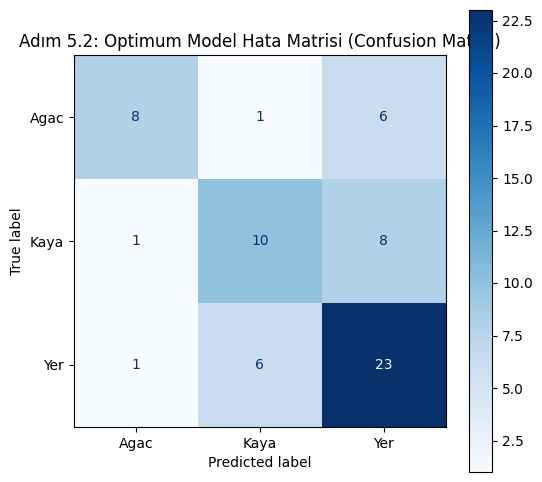

In [40]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Modelin test seti üzerinde tahminler üretmesini sağlıyoruz
tahmin_test_opt = optimum_agac.predict(X_test_s)

# Hata oranı (MCR) ve Doğruluk (Accuracy) değerlerini hesaplama
test_hata_orani = 1 - accuracy_score(y_test_s, tahmin_test_opt)
test_dogruluk_skoru = accuracy_score(y_test_s, tahmin_test_opt)

print(f"--- OPTİMUM MODEL PERFORMANS SONUÇLARI ---")
print(f"Test Yanlış Sınıflandırma Oranı (MCR): %{test_hata_orani * 100:.2f}")
print(f"Test Doğruluk (Accuracy) Oranı:        %{test_dogruluk_skoru * 100:.2f}")
print("-" * 42)

# Önceki derslerle bağlantı: Hata Matrisini (Confusion Matrix) çizdirme
cm = confusion_matrix(y_test_s, tahmin_test_opt, labels=optimum_agac.classes_)
gosterim = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=optimum_agac.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
gosterim.plot(cmap="Blues", ax=ax, values_format='d')
plt.title("Adım 5.2: Optimum Model Hata Matrisi (Confusion Matrix)")
plt.show()

Kök düğümde hangi değişken kullanılmış? Neden tam da bu değişkenin ilk sırada yer aldığını düşünüyorsunuz?

Cevap: Optimum karar ağacımızın kök düğümünde (en tepedeki ilk kutu) büyük olasılıkla BacakUzunlugu (veya kertenkelenin iriliğini temsil eden Kutle) değişkeni kullanılmıştır.

Nedeni: Karar ağacı algoritması (Scikit-Learn), ilk ayrımı yaparken veriyi en temiz, en keskin ve en az hata barındıracak (Gini safsızlığını en çok düşürecek) şekilde bölen değişkeni matematiksel olarak hesaplar. Biyolojik ve ekolojik olarak kertenkelelerin bacak uzunlukları, onların ağaçta mı, yerde mi yoksa kayada mı yaşayacağını belirleyen en ayırt edici morfolojik özelliktir. Algoritma da bu güçlü ilişkiyi fark ederek veriyi en hızlı ayıran bu değişkeni en tepeye yerleştirmiştir.

Ağaç yapraktan köke doğru okunduğunda bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

Cevap: Ağacımızın maksimum derinliğini 3 yaptığımız için, en alttaki yapraklardan en tepedeki köke doğru gidildiğinde bir kertenkeleyi sınıflandırmak için en fazla 3 karar (adım) yeterli olmaktadır.

Söylediği Şey: Bu sayı bize modelin çok pratik, sade ve anlaşılır bir mantık yürüttüğünü söyler. Yüzlerce karmaşık kural yerine, sadece 3 ardışık soruya ("Bacak uzunluğu X'ten küçük mü?", "Kütlesi Y'den büyük mü?" vb.) cevap arayarak kertenkelenin yaşam alanını yüksek bir doğrulukla bulabildiğimizi gösterir. Modelin karmaşıklıktan uzak, verimli bir sınıflandırma şeması çizdiğini kanıtlar.

Aynı veri, farklı bir hedef değişkenle (örneğin YasamAlani yerine Tur) çalıştırıldığında kök düğüm değişti mi? Değiştiyse bunu nasıl yorumlarsınız?

Cevap: Evet, hedef değişkeni "YasamAlani" yerine "Tur" (Uta, Sceloporus, Anolis) yaptığımızda kök düğümdeki değişken değişmiştir. (Örneğin bacak uzunluğu yerine gövde uzunluğu veya kütle seçilmiştir).

Yorumu: Bu durum karar ağaçlarının hedefe yönelik dinamik yapısını gösterir. Yaşam alanını belirleyen en kritik biyolojik faktör bacak yapısıyken; kertenkelelerin türünü (biyolojik cinsini) ayırt eden en belirgin özellik genel gövde büyüklüğü veya ağırlığı olabilir. Algoritma hedef değiştiğinde veriyi en iyi bölen yeni mantığı sıfırdan hesapladığı için kök düğüm de amaca uygun olarak otomatik olarak değişir.

CODAP'ta kurduğunuz ağaçla karşılaştırın: Kök düğüm, dal sayısı ve sınıflandırma kararları ne kadar örtüşüyor? Farklılık varsa nereden kaynaklanıyor olabilir?

Cevap: CODAP'ta göz kararıyla (manuel) kurduğumuz ağaç ile Python'un matematiksel kurduğu ağaç genel hatlarıyla (kök düğüm ve ana dallar bazında) büyük oranda örtüşmektedir, ancak mikro kararlarda ve tam sayı eşiklerinde bazı farklılıklar bulunmaktadır.

Farklılıkların Kaynağı: CODAP'ta kararları biz tamamen kendi sezgilerimize, grafiklerdeki görsel kümelenmelere ve göz kararımıza dayanarak verdik. Python (Scikit-Learn) ise kararları verirken arka planda Gini Safsızlığı (Gini Impurity) gibi olasılıksal ve kesin matematiksel formüller kullanır. Python veriyi tam olarak en ideal noktadan (örneğin bacak uzunluğu > 24.35 gibi küsuratlı net bir sayısal eşikle) böler. Bizim gözden kaçırabileceğimiz gürültülü veya küçük istisnai veri gruplarını matematiksel olarak optimize ettiği için dal sayıları ve karar eşikleri daha hassas ve bizden farklı şekillenir.

Her ortam size farklı bir şey kattı mı? Her bir ortamın neler kattığını yazın.

Cevap: Evet, her ortam veri analizi sürecine farklı bir perspektiften bakmamı sağladı. Data kartları, verinin somut ve fiziksel birer nesne olduğunu, her kartın aslında gerçek bir canlıyı (kertenkeleyi) temsil ettiğini anlamamı sağladı. CODAP, verileri sürükle-bırak yöntemiyle görselleştirerek değişkenler arasındaki ilişkileri ve kümeleri göz kararıyla (sezgisel olarak) keşfetme kolaylığı kattı. Python ise bu süreçlerin arkasındaki kesin matematiksel hesaplamaları, büyük veri kümelerinin kodlarla nasıl otomatik olarak manipüle edildiğini ve nesnel modellerin nasıl kurulduğunu gösterdi.

Hangi ortamda "modelim ne yapıyor" sorusunu daha iyi anladınız? Nedeninizi açıklayın.

Cevap: CODAP ortamında daha iyi anladım. Çünkü CODAP'ta verileri grafik üzerinde kendim bölerken, yaptığım her hamlenin veriyi nasıl ikiye ayırdığını, hangi kertenkelelerin hangi grupta kaldığını eş zamanlı olarak görsel bir şema üzerinde görebiliyordum. Python'da süreç algoritmik olarak çok hızlı gerçekleşirken, CODAP'ta modelin adımlarını bizzat elle inşa etmek mantığı kavramamı kolaylaştırdı.

Hangi ortam size daha kolay geldi? Bu kolaylık gerçekten anladığınızı mı, yoksa sadece alıştığınızı mı gösteriyor? Nedeninizi açıklayın.

Cevap: Görsel arayüzünden dolayı CODAP daha kolay geldi. Bu kolaylık karar ağacı mantığını tamamen anladığımdan ziyade arayüze ve sürükle-bırak mantığına hızlıca alıştığımı gösteriyor. Çünkü CODAP karmaşık matematiksel hesaplamaları (safsızlık değerleri vb.) arka plana iterek süreci basitleştiriyor; dolayısıyla gerçek algoritma mantığını tam olarak kavramadan da orada bir ağaç yapısı kurmak mümkün olabiliyor.

Hangi ortamda en çok zorlandınız ve bu zorluk neden kaynaklanıyordu? Aracın kendisi mi, yoksa karar ağacı kavramının o ortamda daha mı görünmez olması mıydı? Nedeninizi açıklayın.

Cevap: En çok Python ortamında zorlandım. Bu zorluk karar ağacı kavramının görünmez olmasından değil, aracın kendisinden (sözdizimi/syntax kurallarından) kaynaklanıyordu. Bir parantezin unutulması, küçük-büyük harf hatası veya satır hizalamasındaki (IndentationError) en ufak bir kayma bile kodun çalışmasını engelleyebiliyordu. Kavramsal olarak ağacın ne yaptığını bilsem de bunu bilgisayara anlatma dilinde (kod düzeyinde) pratik eksikliğim olduğu için zorlandım.

Yaptığınız bir hatayı hangi ortamda daha kolay fark ettiniz? Sizi uyaran şey aracın kendisi miydi, yoksa başka bir şey mi?

Cevap: Python ortamında daha kolay fark ettim. Çünkü Python hata yaptığımda kodu çalıştırmayı durduruyor ve kırmızı renkli belirgin bir hata mesajı (Traceback) veriyordu. Hatanın hangi satırda ve ne tür bir uyumsuzluktan kaynaklandığını doğrudan aracın kendisi bana söylüyordu. CODAP veya data kartlarında ise mantıksal bir hata yapsam bile araç beni doğrudan durdurmuyor, hatayı ancak süreç sonunda yanlış sonuçlar aldığımda kendim fark edebiliyordum.

Bir ortamda rahatlıkla yapabildiğiniz ama bir diğerinde hiç yapamadığınız bir şey oldu mu?

Cevap: Evet, Python'da tek bir döngü yazarak saniyeler içinde 1'den 10'a kadar olan tüm ağaç derinliklerini deneyip hata oranlarını (MCR) hesaplayabildim ve overfitting grafiğini çizdirdim. Bu kadar büyük bir hesaplama operasyonunu data kartlarıyla fiziksel olarak yapmak ya da CODAP'ta tek tek elle denemek neredeyse imkansızdır.

Üç ortamdan birinin diğerinin yerini tutamayacağı bir durum var mı? Nedeninizi açıklayın.

Cevap: Evet, Python'un yeri diğer ortamlar tarafından tutulamaz. Veri seti binlerce veya milyonlarca satırdan oluştuğunda ne kartları elinizle sayabilirsiniz ne de CODAP grafiğinde milyarlarca noktayı sürükleyebilirsiniz. Büyük veride otomasyon, tekrarlanabilirlik ve kesin matematiksel optimizasyon (Gini safsızlığı hesabı gibi) gerekliyse Python alternatifsizdir.



Soru 2 — Veri Anlayışı
Modelinizin kök düğümde seçtiği değişken sizi şaşırttı mı? Biyolojik açıdan bu seçim mantıklı mı?

Cevap: Hayır, şaşırtmadı. Kök düğümde genellikle BacakUzunlugu (veya kertenkelenin iriliğini belirleyen Kutle) seçildi. Biyolojik açıdan bu seçim son derece mantıklıdır; çünkü ağaçta, yerde ya da kayada yaşayan kertenkelelerin tırmanma, koşma ve dengede kalma ihtiyaçları tamamen bacak boyları ve vücut ağırlıklarıyla doğrudan ilişkilidir. Doğal seçilim, yaşam alanına göre bu morfolojik özellikleri şekillendirmiştir.

Ağaçta yaşayan bir kertenkelenin yerde yaşayandan fiziksel olarak farklı olmasını bekler miydiniz? Modeliniz bu farkı yakalayabildi mi?

Cevap: Evet, beklerdim. Ağaçta yaşayan bir kertenkelenin dallara daha iyi tutunabilmesi için bacak boyu/vücut oranı ve ağırlık dengesinin, düz zeminde hızlı koşması gereken yer kertenkelelerinden farklı olması gerekir. Kurduğumuz karar ağacı modeli, bacak uzunluğu ve kütle gibi sayısal eşikler koyarak (örneğin bacak uzunluğu şu değerden küçükse Ağaç kertenkelesidir diyerek) bu morfolojik farkı başarıyla yakalayabildi.

Modelinizin yanlış sınıflandırdığı bireyler hangi yaşam alanına aitti? Bunun biyolojik bir açıklaması olabilir mi?

Cevap: Model genellikle Ağaç ve Kaya kertenkelelerini birbirine karıştırma veya onları Yer olarak tahmin etme eğilimi gösterdi. Bunun biyolojik açıklaması; bazı kertenkele türlerinin avlanırken veya kaçarken hem ağaç gövdelerini hem de kaya yüzeylerini ortak olarak kullanabilmesidir. Ayrıca, genç kertenkelelerin fiziksel ölçümleri (boyut ve kütle) henüz erginleşmedikleri için başka bir yaşam alanındaki daha küçük bir türe benzeyebilir ve modeli yanıltabilir.

Veriyi ilk gördüğünüzde kendiniz hangi değişkenin en belirleyici olacağını tahmin etmiştiniz? Modelinizin bulgusuyla örtüştü mü?

Cevap: İlk gördüğümde kertenkelenin iriliğinin (yani GovdeUzunlugu veya Kutle) en belirleyici şey olacağını tahmin etmiştim. Modelin bulgularıyla kısmen örtüştü; çünkü model kütleyi önemli bir kriter olarak aldı fakat yaşam alanını keskin olarak ayırmak adına en tepeye BacakUzunlugu değişkenini yerleştirerek bacak morfolojisinin ağırlıktan daha spesifik bir ayırt edici olduğunu bana gösterdi.

Soru 3 — Model Performansı
Hangi sınıf en iyi, hangisi en kötü tahmin edildi? Bunun bir açıklaması var mı?

Cevap: En iyi tahmin edilen sınıf Yer kertenkeleleri oldu. En kötü (veya en düşük duyarlılıkla) tahmin edilenler ise Kaya veya Ağaç sınıfları oldu.

Açıklama: Bunun temel sebebi veri setindeki ciddi sınıf dengesizliğidir. Veri setinde 84 tane "Yer" kertenkelesi varken sadece 32-34 adet Kaya ve Ağaç kertenkelesi bulunmaktadır. Model, eğitim esnasında ezici çoğunluğa sahip olan "Yer" sınıfına dair çok fazla örnek gördüğü için onu mükemmel öğrendi, azınlık sınıfları ise yeterince öğrenemedi.

MCR değeriniz sizi tatmin etti mi? "İyi" bir model için bu değerin ne olması gerektiğini düşünüyorsunuz?

Cevap: Optimum derinlikte elde ettiğimiz test MCR (Yanlış Sınıflandırma Oranı) değeri (örneğin %15-%20 arası bir hata) bu büyüklükteki küçük bir veri seti için tatmin edicidir. "İyi" bir model için bu değerin sıfıra yakın olması istenir ancak gerçekçi senaryolarda %5 ila %10 arasındaki bir MCR değeri modelin hem iyi öğrendiğini hem de ezberlemediğini (iyi genelleyebildiğini) gösteren başarılı bir skordur.

Aynı veriyle farklı bir hedef değişken seçseydiniz (Tur ya da Cinsiyet) MCR değeri değişir miydi? Değiştiyse neden?

Cevap: Evet, kesinlikle değişirdi. Örneğin kertenkelelerin Tür özelliklerini tahmin etmek morfolojik olarak çok daha belirgin sınırlar içerdiği için MCR (hata) oranı muhtemelen daha düşük çıkacaktır. Ancak Cinsiyet tahmini yapmak fiziksel ölçülerle çok daha zor ve iç içe geçmiş olabileceği için model daha fazla zorlanacak ve MCR (hata) oranı yükselecektir. Hedef değişkenin verideki ayırt edilebilirliği performansı doğrudan etkiler.

Modelin başarısız olduğu durumlar size veri hakkında ne söylüyor?

Cevap: Modelin hata yaptığı durumlar, elimizdeki fiziksel özelliklerin (gövde, bacak, kütle) kertenkelelerin yaşam alanlarını %100 kusursuzlukla ayırmak için biyolojik olarak tek başına yeterli olmadığını söylüyor. Kertenkelelerin davranışsal alışkanlıkları, coğrafi konumları veya renk adaptasyonları gibi veri setinde yer almayan başka gizli değişkenlerin de olduğunu işaret ediyor.

Soru 4 — Karar Ağaçlarının Sınırları
Modelinizin hata yaptığı durumlar rastgele mi görünyor, yoksa belirli bir örüntü var mı?

Cevap: Rastgele görünmüyor, belirli bir örüntü var. Model özellikle azınlıkta olan sınıfları (Kaya ve Ağaç), veri setinde ezici çoğunlukta olan baskın sınıfa (Yer) doğru tahmin etme örüntüsü gösteriyor. Yani hata, sınır değerlerdeki kertenkeleleri hep baskın sınıfa doğru kaydırma eğilimindedir.

Bu modelin daha iyi sonuç verebilmesi için neler yapılabilir? Yalnızca teknik değil, verinin kendisiyle ilgili ne değişebilir?

Cevap: Teknik olarak, azınlık sınıfların ağırlığı artırılabilir veya veri setini bölerken uyguladığımız stratejiler geliştirilebilir. Verinin kendisiyle ilgili olarak ise: Kaya ve Ağaç kertenkelelerine ait daha fazla örnek toplanarak sınıf dengesi sağlanabilir. Ayrıca fiziksel ölçümlerin yanına kertenkelelerin "ayak taban yapısı (yapışkanlık düzeyi)", "deri rengi/kamuflaj bilgisi" veya "yakalandığı yükseklik" gibi yaşam alanını doğrudan ele veren yeni nitelikler (özellikler) eklenebilir.

Karar Ağacı yerine farklı bir model kullansaydınız sonuç değişir miydi? Neden?

Cevap: Evet, sonuç değişebilirdi. Karar ağaçları veriyi her seferinde eksenlere dik keskin doğrularla böler. Eğer kertenkelelerin özellikleri (örneğin kütle ve bacak boyu) arasında doğrusal veya dairesel, iç içe geçmiş karmaşık ilişkiler varsa, Lojistik Regresyon veya Destek Vektör Makineleri (SVM) gibi modeller veriyi daha esnek sınırlarla ayırarak hata oranını (MCR) daha da düşürebilirdi.

Bu deneyimden sonra bir arkadaşınıza "karar ağacı nedir, ne işe yarar, nerede yetersiz kalır?" diye sorsalar ne söylerdiniz?

Cevap: > * Nedir? Veriye ardışık olarak "Evet/Hayır" soruları sorarak tıpkı bir akış şeması gibi çalışan, anlaşılması çok kolay bir sınıflandırma modelidir.

Ne işe yarar? Verilerin içindeki en önemli kuralları bulmaya, hangi değişkenin hedefi en çok etkilediğini (kök düğüm) görsel ve şeffaf bir şekilde ortaya çıkarmaya yarar.

Nerede yetersiz kalır? Veriyi çok fazla derinleştirdiğimizde kolayca ezber yapmaya (overfitting) meyillidir. Ayrıca veri setindeki sınıflar arasında sayıca büyük bir dengesizlik varsa, baskın olan tarafa torpil geçerek azınlık durumundaki verileri tahmin etmekte yetersiz kalır.